In [1]:
import numpy as np
import os 
import re
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler



def calculate_metrics(y_true, y_pred):
    """
    合并计算所有指标：RMSE、MAE、sMAPE、R2
    返回一个字典
    """
    # RMSE
    rmse_val = np.sqrt(np.mean((y_true - y_pred) ** 2))
    # MAE
    mae_val = np.mean(np.abs(y_true - y_pred))
    # sMAPE
    smape_val = 100 * np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred)))
    # R2
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2_val = 1 - (ss_res / ss_tot)
    
    return {
        'rmse': rmse_val,
        'mae': mae_val,
        'smape': smape_val,
        'r2': r2_val
    }
    
standard_scaler = StandardScaler()
data = pd.read_csv('dataset/GLD.csv')
data.set_index('date', inplace=True)
data_values = data['Close'].values.reshape(-1, 1)
standard_scaler.fit(data_values)

metrics_list = []

# prefix = 'results_Proximal_20260118'
prefix = 'results'

for f in tqdm(os.listdir(prefix)):
    if os.path.isdir(os.path.join(prefix, f)):
        pattern = re.compile(r'''
            ^
            long_term_forecast_
            (?P<model_id>.+?)_
            GLD_
            (?P<model>.+?)_
            custom_
            ft(?P<features>[^_]+)_
            sl(?P<seq_len>\d+)_
            ll(?P<label_len>\d+)_
            pl(?P<pred_len>\d+)_
            dm(?P<d_model>\d+)_
            nh(?P<n_heads>\d+)_
            el(?P<e_layers>\d+)_
            dl(?P<d_layers>\d+)_
            df(?P<d_ff>\d+)_
            fc(?P<factor>\d+)_
            eb(?P<embed>[^_]+)_
            dt(?P<distil>[^_]+)_
            (?P<des>[^_]+)_
            (?P<ii>[^_]+)
            $
        ''', re.VERBOSE)

        m = pattern.match(f)
        if m:
            params = m.groupdict()
            pred = np.load(os.path.join(prefix, f, 'pred.npy'))
            true = np.load(os.path.join(prefix, f, 'true.npy'))
            pred = pred[:, -1, 0]
            true = true[:, -1, 0]
            pred = standard_scaler.inverse_transform(pred.reshape(-1, 1))
            true = standard_scaler.inverse_transform(true.reshape(-1, 1))
            metrics = calculate_metrics(true, pred)
            metrics_list.append({**params, **metrics})
        else:
            print(f"Folder name '{f}' doesn't match expected pattern.")
            continue

metrics_df = pd.DataFrame(metrics_list)
metrics_df['seq_len'] = metrics_df['seq_len'].astype(int)
metrics_df['pred_len'] = metrics_df['pred_len'].astype(int)
metrics_df['label_len'] = metrics_df['label_len'].astype(int)
metrics_df = metrics_df.sort_values(by=['model', 'seq_len', 'pred_len'])
metrics_df.to_excel('metrics_summary.xlsx', index=False)
print('model id:', metrics_df['model_id'].unique())
print('model name:', metrics_df['model'].unique())
print('lebel len:', metrics_df['label_len'].unique())
print('seq len:', metrics_df['seq_len'].unique())


100%|██████████| 27442/27442 [00:15<00:00, 1812.05it/s]


model id: ['AutoConNet_LastVal' 'AutoConNet_Mean' 'AutoConNet_Decomp'
 'AutoConNet_ReVIN' 'Autoformer' 'Crossformer' 'DLinear' 'FiLM' 'MICN'
 'NLinear' 'Nonstationary_Transformer' 'PatchTST'
 'Proximal_Nonstationary_Transformer_Median'
 'Proximal_Nonstationary_Transformer_Mean'
 'Proximal_Nonstationary_Transformer_LastVal' 'Pyraformer' 'TimesNet'
 'Transformer']
model name: ['AutoConNet' 'Autoformer' 'Crossformer' 'DLinear' 'FiLM' 'MICN' 'NLinear'
 'Nonstationary_Transformer' 'PatchTST'
 'Proximal_Nonstationary_Transformer' 'Pyraformer' 'TimesNet'
 'Transformer']
lebel len: [  8  16  32  48  64  96 128 160 192]
seq len: [ 16  32  64  96 128 192 256 320 384]


<Axes: xlabel='pred_len'>

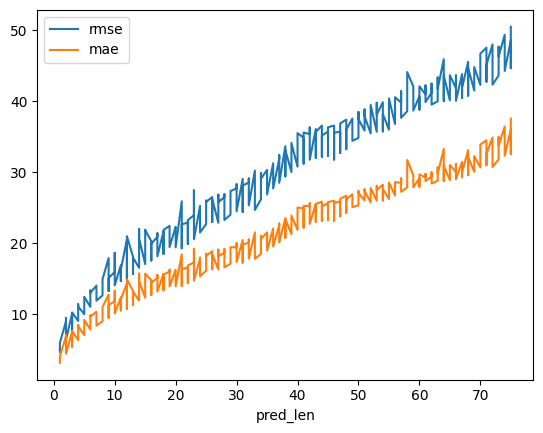

In [2]:
metrics = metrics_df.set_index('pred_len')
metrics = metrics[(metrics['seq_len']==96) & (metrics['model']=='Proximal_Nonstationary_Transformer')]
metrics = metrics.sort_index()
metrics[['rmse', 'mae']].plot()

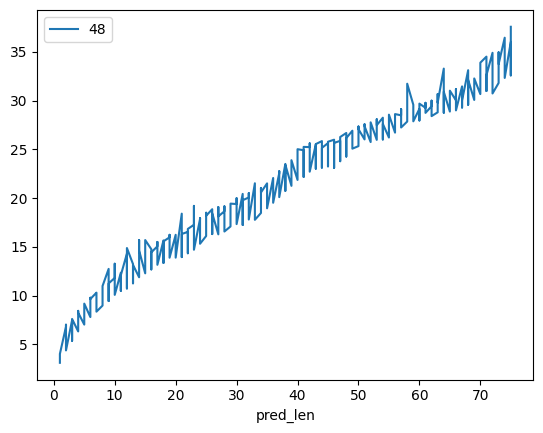

In [3]:
metrics_df = pd.read_excel('metrics_summary.xlsx')
metrics = metrics_df.set_index('pred_len')
metrics = metrics[(metrics['seq_len']==96) & (metrics['model']=='Proximal_Nonstationary_Transformer')]
metrics = metrics.groupby('label_len')
# metrics = metrics.sort_index()
metrics['mae'].plot()
plt.legend()

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
metrics_df = pd.read_excel('metrics_summary.xlsx')
metrics = metrics_df.set_index('pred_len')
metrics = metrics.groupby('model')
aggregated = metrics_df.groupby(['model', 'seq_len'])['rmse'].agg(['mean', 'max', 'min']).reset_index()
aggregated.columns = ['model', 'seq_len', 'rmse_mean', 'rmse_max', 'rmse_min']
print('RMSE Metrics Summary by Model and Seq_Len')
print(aggregated)

aggregated_mae = metrics_df.groupby(['model', 'seq_len'])['mae'].agg(['mean', 'max', 'min']).reset_index()
aggregated_mae.columns = ['model', 'seq_len', 'mae_mean', 'mae_max', 'mae_min']
print('MAE Metrics Summary by Model and Seq_Len')
print(aggregated_mae)

aggregated_smape = metrics_df.groupby(['model', 'seq_len'])['smape'].agg(['mean', 'max', 'min']).reset_index()
aggregated_smape.columns = ['model', 'seq_len', 'smape_mean', 'smape_max', 'smape_min']
print('SMAPE Metrics Summary by Model and Seq_Len')
print(aggregated_smape)

aggregated_r2 = metrics_df.groupby(['model', 'seq_len'])['r2'].agg(['mean', 'max', 'min']).reset_index()
aggregated_r2.columns = ['model', 'seq_len', 'r2_mean', 'r2_max', 'r2_min']
print('R2 Metrics Summary by Model and Seq_Len')
print(aggregated_r2)

RMSE Metrics Summary by Model and Seq_Len
           model  seq_len   rmse_mean    rmse_max    rmse_min
0     AutoConNet       16  107.156169  245.689728    4.634182
1     AutoConNet       32  109.649894  235.891632    5.010599
2     AutoConNet       64  107.810250  236.360046    4.670302
3     AutoConNet       96  107.406543  237.953201    5.586428
4     AutoConNet      128  106.768738  244.179245    5.279208
..           ...      ...         ...         ...         ...
112  Transformer      128  126.906824  143.592041  103.709923
113  Transformer      192  126.249748  149.751938  103.158195
114  Transformer      256  127.279111  145.651794  100.141273
115  Transformer      320  124.860908  147.244476   99.442154
116  Transformer      384  130.378204  155.180710  101.920990

[117 rows x 5 columns]
MAE Metrics Summary by Model and Seq_Len
           model  seq_len   mae_mean     mae_max    mae_min
0     AutoConNet       16  84.171556  223.532074   3.137464
1     AutoConNet       32  85

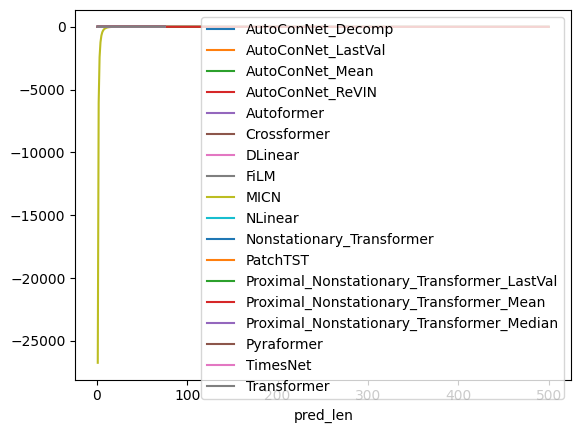

In [5]:
metrics_df = pd.read_excel('metrics_summary.xlsx')
metrics = metrics_df.set_index('pred_len')
metrics = metrics[(metrics['seq_len']==96)]
metrics = metrics.groupby('model_id')
# metrics = metrics.sort_index()
metrics['r2'].plot()
plt.legend()

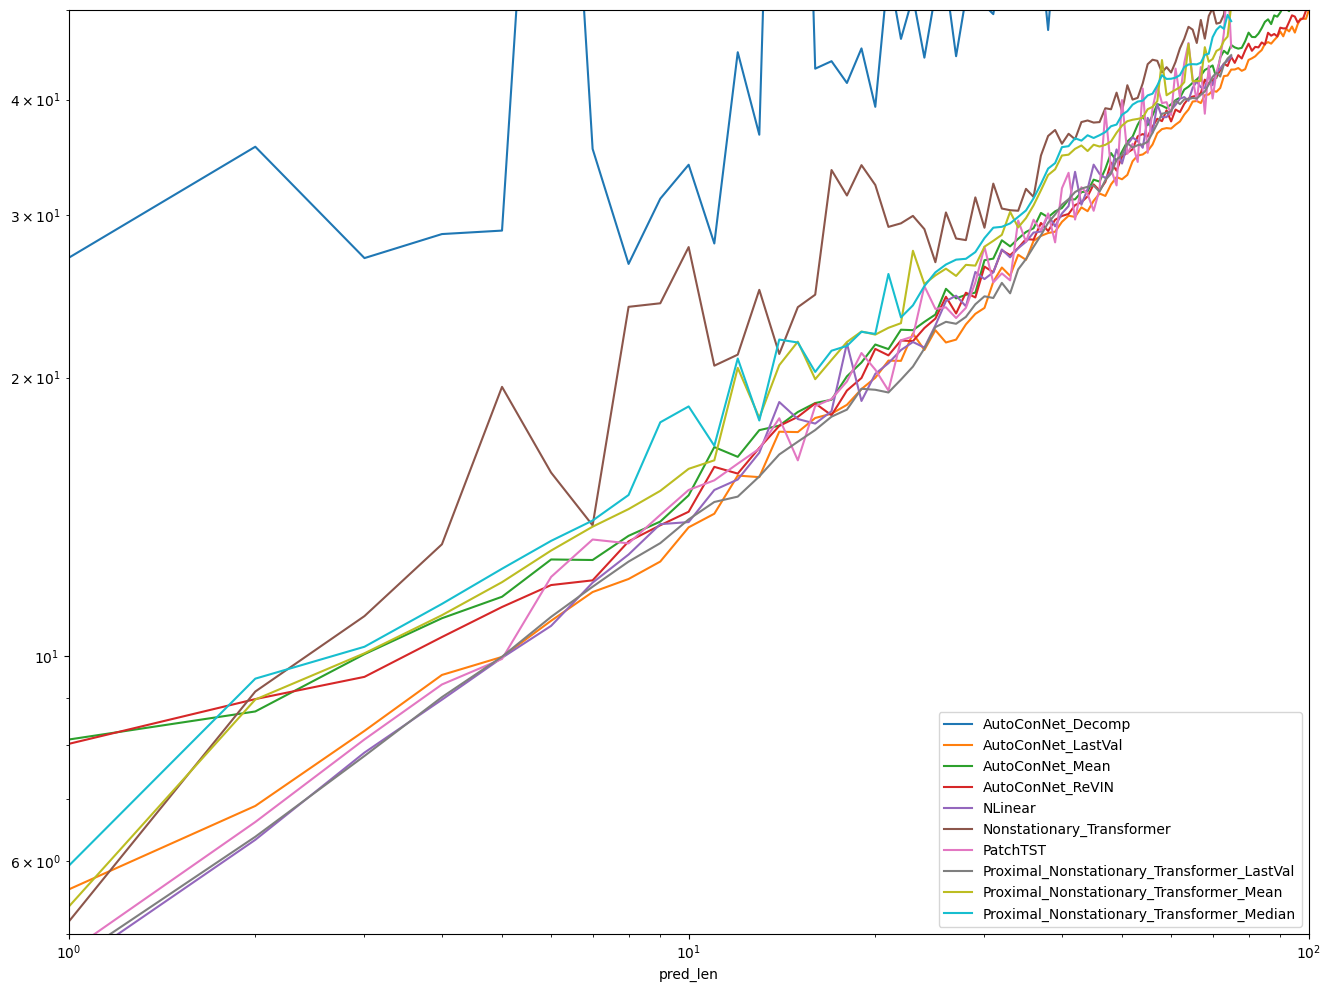

In [6]:
plt.figure(figsize=(16,12))
metrics_df = pd.read_excel('metrics_summary.xlsx')
metrics = metrics_df.set_index('pred_len')
metrics = metrics[(metrics['seq_len']==96)]
metrics = metrics[metrics['model_id'].str.contains('AutoConNet|Nonstationary|PatchTST|NLinear')]
metrics = metrics.groupby('model_id')
# metrics = metrics.sort_index()
metrics['rmse'].plot()
plt.legend()
metrics['rmse'].mean().sort_values()
plt.ylim(5,50)
plt.xlim(1,100)
plt.yscale('log')
plt.xscale('log')